# Task 2 — Pipeline Proposal & Baseline Experimentation
**Hypothesis:** global geopolitical news helps predict next-day moves of the US Dollar (FRED `DTWEXBGS`, Nominal Broad USD Index).

This notebook is the exploratory + experimental companion to the `src/` package:
1. Why the Task 1 daily table had to be re-aligned to trading days
2. EDA of the exchange-rate series (stationarity, autocorrelation)
3. EDA of the NLP features (category volume, news shocks, relation to next-day returns — **train split only**)
4. Baseline (history only) vs. combined (history + NLP) results on validation and test

All modelling code lives in `src/`; the notebook only calls it.

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, acf
from src.task2 import config
from src.task2.run_pipeline import build_dataset, run

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
FIG = config.FIGURES; FIG.mkdir(parents=True, exist_ok=True)

# chart styling: recessive axes, thin marks, fixed role colours
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#a3a29c"
CAT_COLORS = dict(zip(config.CATEGORIES, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "font.size": 9, "legend.frameon": False, "axes.axisbelow": True})

## 1. Correcting the Task 1 target: calendar days → trading days
Task 1 forward-filled the USD index over weekends/holidays, so every Friday and Saturday row has a "next-day change" of exactly 0 — labelled **DOWN**.

In [2]:
t1 = pd.read_csv(config.NEWS_DAILY_FILE, parse_dates=["date"])
t1["weekday"] = t1["date"].dt.day_name()
tab = t1.groupby("weekday").agg(rows=("usd_direction_next", "size"),
                                 share_UP=("usd_direction_next", "mean"),
                                 share_zero_change=("usd_pct_change_next", lambda s: (s == 0).mean()))
display(tab.reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).round(3))
print(f"Rows with exactly 0% change: {(t1.usd_pct_change_next == 0).mean():.1%}")
print(f"Task 1 UP share: {t1.usd_direction_next.mean():.1%}  -> 'always DOWN' scores {1 - t1.usd_direction_next.mean():.1%} by construction")

,rows,share_UP,share_zero_change
weekday,,,
Monday,261,0.536,0.008
Tuesday,261,0.421,0.015
Wednesday,260,0.481,0.035
Thursday,260,0.473,0.019
Friday,260,0.000,1.000
Saturday,260,0.000,1.000
Sunday,260,0.442,0.131


Rows with exactly 0% change: 31.5%
Task 1 UP share: 33.6%  -> 'always DOWN' scores 66.4% by construction


**Fix (in `src/data_prep.py`):** keep only real trading days; news from weekends/holidays is summed onto the next trading day (Monday gets Sat+Sun+Mon) instead of being discarded. Target = next trading day's log return $r_{t+1}=\ln(P_{t+1}/P_t)$; direction = $1[r_{t+1}>0]$.

In [3]:
df, feature_sets, _ = build_dataset(verbose=True)
print(df.shape)
display(df.groupby("split").agg(start=("date","min"), end=("date","max"), rows=("date","size"),
                                UP_share=("target_up_next","mean")).loc[["train","val","test"]])

[info] nyt_geopolitical_articles_clean.csv not found -> text features skipped; using lexicon category-count features only.
(1228, 39)


,start,end,rows,UP_share
split,,,,
train,2021-02-03,2024-07-09,859,0.479627
val,2024-07-10,2025-04-03,184,0.570652
test,2025-04-04,2025-12-30,185,0.481081


## 2. EDA — exchange-rate series

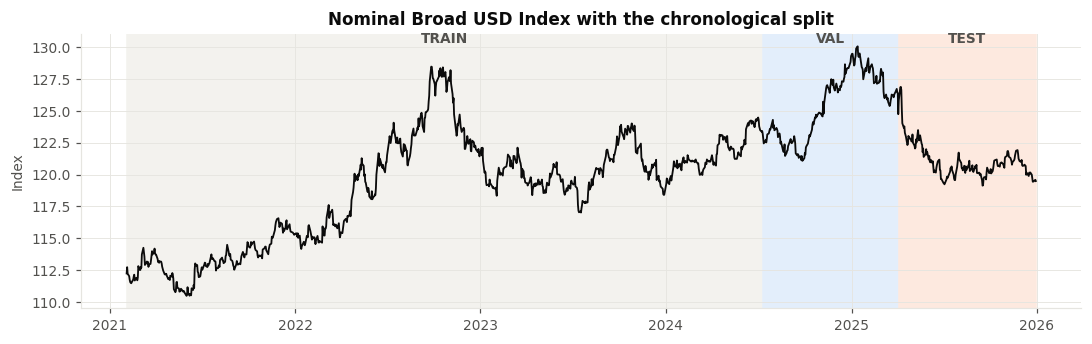

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(df.date, df.usd_index, color=INK, lw=1.2)
shade = {"train": "#f3f2ee", "val": "#e3eefb", "test": "#fde9df"}
for s in ("train", "val", "test"):
    d = df[df.split == s]
    ax.axvspan(d.date.min(), d.date.max(), color=shade[s], zorder=0)
    ax.text(d.date.min() + (d.date.max() - d.date.min()) / 2, df.usd_index.max() + 0.3, s.upper(),
            ha="center", color=INK2, fontsize=9, fontweight="bold")
ax.set_title("Nominal Broad USD Index with the chronological split"); ax.set_ylabel("Index")
fig.tight_layout(); fig.savefig(FIG / "usd_split.png", dpi=200); plt.show()

ADF p-value  level: 0.432 (non-stationary)   log-return: 1.85e-14 (stationary -> d=0 on returns)


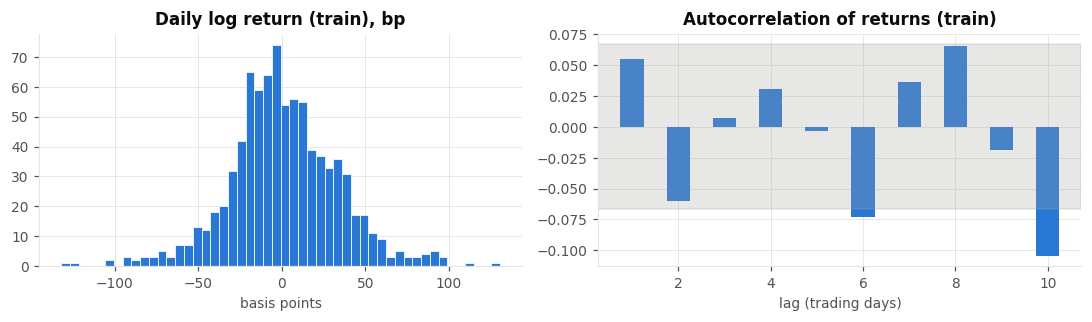

Return stats (bp): {'count': 859.0, 'mean': 1.1, 'std': 32.75, 'min': -132.0, '25%': -17.75, '50%': -1.45, '75%': 20.71, 'max': 130.6}


In [5]:
tr = df[df.split == "train"]
adf_lvl = adfuller(tr.usd_index)[1]; adf_ret = adfuller(tr.ret.dropna())[1]
print(f"ADF p-value  level: {adf_lvl:.3f} (non-stationary)   log-return: {adf_ret:.2e} (stationary -> d=0 on returns)")
ac = acf(tr.ret.dropna(), nlags=10)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(tr.ret * 1e4, bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_title("Daily log return (train), bp"); axes[0].set_xlabel("basis points")
band = 1.96 / np.sqrt(len(tr))
axes[1].bar(range(1, 11), ac[1:], color=BLUE, width=0.5)
axes[1].axhspan(-band, band, color=GRAY, alpha=0.25)
axes[1].set_title("Autocorrelation of returns (train)"); axes[1].set_xlabel("lag (trading days)")
fig.tight_layout(); fig.savefig(FIG / "returns_acf.png", dpi=200); plt.show()
print("Return stats (bp):", (tr.ret * 1e4).describe().round(2).to_dict())

Returns are close to white noise (autocorrelations inside the 95% band), which is why a random walk is a hard benchmark and why the ARIMA baseline is not expected to do much better than 0.

## 3. EDA — NLP features (train split only, to avoid peeking at val/test)

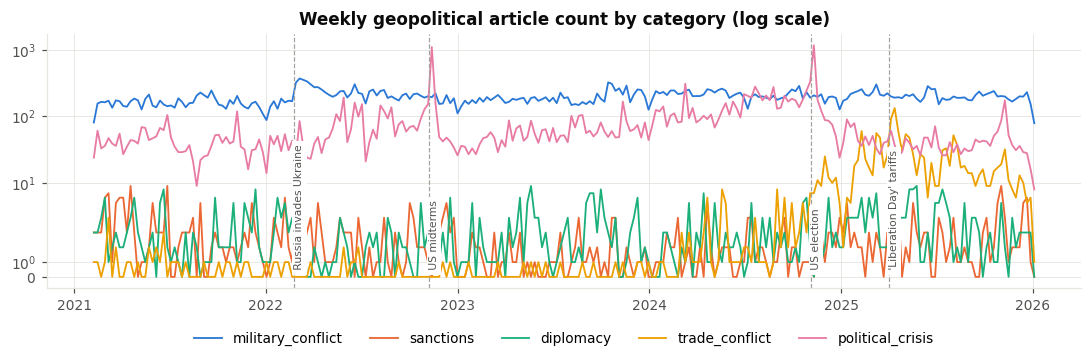

In [6]:
wk = df.set_index("date")[config.CATEGORIES].resample("W").sum()
fig, ax = plt.subplots(figsize=(10, 3.4))
for c in config.CATEGORIES:
    ax.plot(wk.index, wk[c], lw=1.2, color=CAT_COLORS[c], label=c)
ax.set_yscale("symlog", linthresh=5); ax.set_title("Weekly geopolitical article count by category (log scale)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
for d, lab in [("2022-02-24", "Russia invades Ukraine"), ("2022-11-08", "US midterms"), ("2024-11-05", "US election"), ("2025-04-02", "'Liberation Day' tariffs")]:
    ax.axvline(pd.Timestamp(d), color=GRAY, lw=0.8, ls="--"); ax.text(pd.Timestamp(d), 0.3, " " + lab, fontsize=7, color=INK2, rotation=90, va="bottom", bbox=dict(fc="white", ec="none", pad=1.5))
fig.tight_layout(); fig.savefig(FIG / "news_volume.png", dpi=200); plt.show()

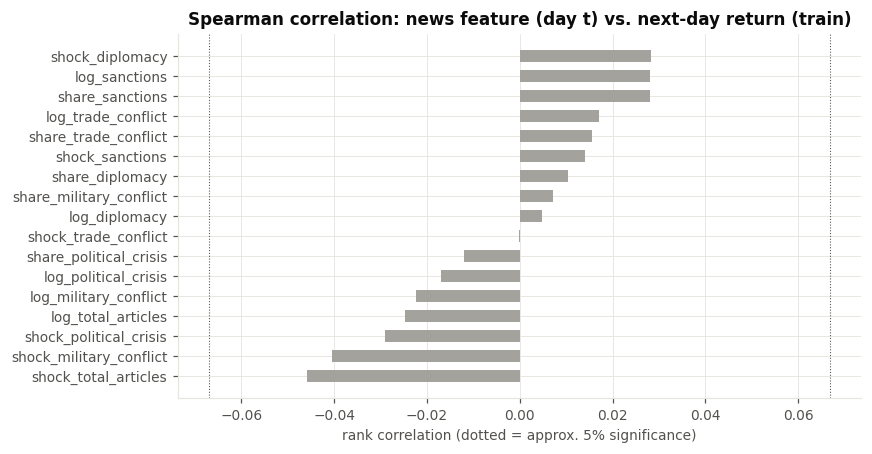

,spearman_rho
shock_total_articles,-0.046
shock_military_conflict,-0.040
shock_political_crisis,-0.029
shock_diplomacy,0.028
log_sanctions,0.028
share_sanctions,0.028
log_total_articles,-0.025
log_military_conflict,-0.022
log_trade_conflict,0.017
log_political_crisis,-0.017


In [7]:
news_cols = feature_sets["market+news"][len(feature_sets["market"]):]
corr = tr[news_cols + ["target_ret_next"]].corr(method="spearman")["target_ret_next"].drop("target_ret_next")
n = len(tr); crit = 1.96 / np.sqrt(n)
fig, ax = plt.subplots(figsize=(8, 4.2))
cs = corr.sort_values()
ax.barh(cs.index, cs.values, color=[ORANGE if abs(v) > crit else GRAY for v in cs.values], height=0.6)
ax.axvline(crit, color=INK2, lw=0.7, ls=":"); ax.axvline(-crit, color=INK2, lw=0.7, ls=":")
ax.set_title("Spearman correlation: news feature (day t) vs. next-day return (train)")
ax.set_xlabel("rank correlation (dotted = approx. 5% significance)")
fig.tight_layout(); fig.savefig(FIG / "news_corr.png", dpi=200); plt.show()
display(corr.round(3).sort_values(key=abs, ascending=False).to_frame("spearman_rho"))

Univariate links between news volume and the next-day return are weak. That is the realistic prior for daily FX: any signal is small, so the combined model must be judged against the baseline on data it has never seen, not by in-sample fit.

## 4. Baseline vs. combined models

In [8]:
df, mv, mt, summary = run(verbose=False)
print("ARIMA order (AIC, train):", summary["arima_order"], "| ARIMAX exog set chosen on val:", summary["arimax_exog_set"])
print("Classifier hyper-parameters (chosen on val macro-F1):"); print(json.dumps(summary["classifier_params"], indent=1))
cols_r = ["model", "features", "RMSE_bp", "MAE_bp", "DirAcc"]
cols_c = ["model", "features", "Accuracy", "MacroF1", "MCC", "AUC", "p_binom(acc>0.5)"]
for name, m in (("VALIDATION", mv), ("TEST (held out)", mt)):
    print(f"\n===== {name} =====")
    display(m[m.track == "regression"][cols_r].round(4))
    display(m[m.track == "classification"][cols_c].round(4))

ARIMA order (AIC, train): [3, 0, 2] | ARIMAX exog set chosen on val: news shock z
Classifier hyper-parameters (chosen on val macro-F1):
{
 "LogReg|market": {
  "C": 1.0
 },
 "LogReg|market+news": {
  "C": 1.0
 },
 "GBM|market": {
  "depth": 3,
  "lr": 0.1,
  "n_iter": 300
 },
 "GBM|market+news": {
  "depth": 2,
  "lr": 0.1,
  "n_iter": 100
 }
}

===== VALIDATION =====


,model,features,RMSE_bp,MAE_bp,DirAcc
0,RandomWalk (0),none,32.8291,24.2504,NaN
3,"ARIMA(3, 0, 2)",market,33.2065,24.1337,0.5598
5,"ARIMAX(3, 0, 2)",news shock z,33.3854,24.2002,0.5000


,model,features,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5)
1,Majority,none,0.4293,0.3004,0.0000,NaN,0.9769
2,Persistence,market,0.5163,0.5072,0.0144,NaN,0.3563
4,"ARIMA(3, 0, 2)-sign",market,0.5598,0.5412,0.0865,NaN,0.0607
6,"ARIMAX(3, 0, 2)-sign",news shock z,0.5000,0.4823,-0.0335,NaN,0.5294
7,LogReg,market,0.5435,0.5426,0.1237,0.5242,0.1344
8,LogReg,market+news,0.4891,0.4842,0.0278,0.5400,0.6437
9,GBM,market,0.5054,0.5053,0.0364,0.4975,0.4706
10,GBM,market+news,0.4946,0.4912,0.0341,0.4939,0.5875



===== TEST (held out) =====


,model,features,RMSE_bp,MAE_bp,DirAcc
0,RandomWalk (0),none,28.5124,21.5495,NaN
3,"ARIMA(3, 0, 2)",market,28.9223,21.7193,0.4595
5,"ARIMAX(3, 0, 2)",news shock z,28.9002,21.5545,0.5297


,model,features,Accuracy,MacroF1,MCC,AUC,p_binom(acc>0.5)
1,Majority,none,0.5189,0.3416,0.0000,NaN,0.3296
2,Persistence,market,0.5459,0.5453,0.0906,NaN,0.1197
4,"ARIMA(3, 0, 2)-sign",market,0.4595,0.4417,-0.0720,NaN,0.8803
6,"ARIMAX(3, 0, 2)-sign",news shock z,0.5297,0.5252,0.0702,NaN,0.2312
7,LogReg,market,0.4649,0.4643,-0.0668,0.5053,0.8483
8,LogReg,market+news,0.5459,0.5291,0.1185,0.5550,0.1197
9,GBM,market,0.5514,0.5460,0.0976,0.5407,0.0928
10,GBM,market+news,0.5189,0.5092,0.0527,0.5220,0.3296


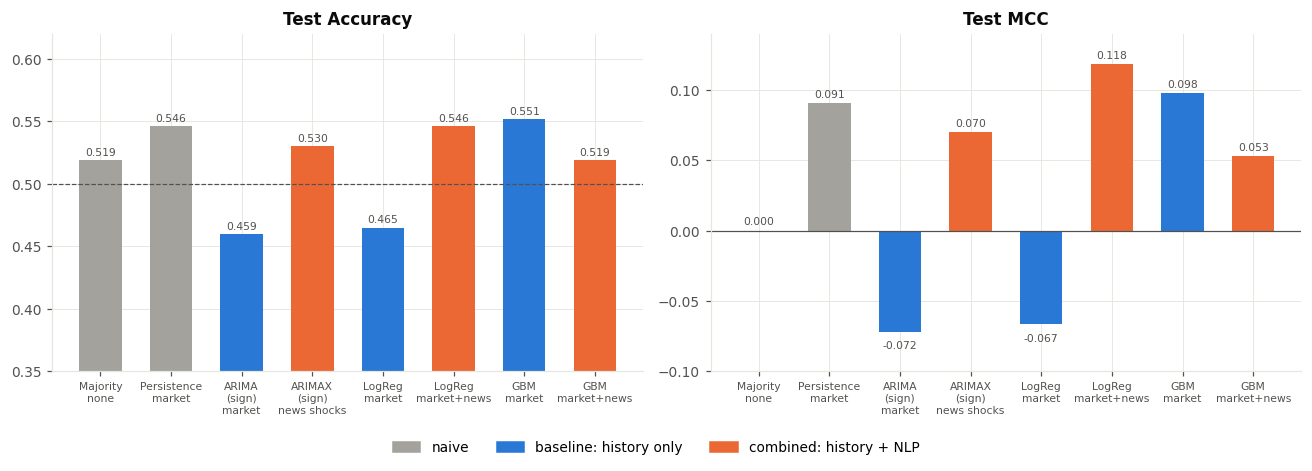

In [9]:
c = mt[mt.track == "classification"].copy()
c["label"] = (c["model"].str.replace(r"\(\d, \d, \d\)", "", regex=True).str.replace("-sign", "\n(sign)")
              + "\n" + c["features"].str.replace("news shock z", "news shocks"))
def colour(f):
    return GRAY if f == "none" else (BLUE if f == "market" else ORANGE)
c["kind"] = np.where(c["model"].isin(["Majority", "Persistence"]), "none", c["features"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, met in zip(axes, ["Accuracy", "MCC"]):
    ax.bar(c["label"], c[met], color=[colour(f) for f in c["kind"]], width=0.6)
    if met == "Accuracy": ax.axhline(0.5, color=INK2, lw=0.8, ls="--"); ax.set_ylim(0.35, 0.62)
    else: ax.axhline(0, color=INK2, lw=0.8); ax.set_ylim(-0.1, 0.14)
    ax.set_title(f"Test {met}"); ax.tick_params(axis="x", labelsize=7, rotation=0)
    for i, v in enumerate(c[met]): ax.text(i, v + (0.004 if v >= 0 else -0.012), f"{v:.3f}", ha="center", fontsize=7, color=INK2)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=GRAY, label="naive"), Patch(color=BLUE, label="baseline: history only"), Patch(color=ORANGE, label="combined: history + NLP")],
           ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIG / "test_classification.png", dpi=200); plt.show()

In [10]:
coef = pd.read_csv(config.RESULTS / "arimax_coefficients.csv", index_col=0)
display(coef.round(5))

,coef,p_value
const,0.00010,0.31763
x1,-0.00021,0.34300
x2,-0.00004,0.73123
x3,-0.00012,0.25914
x4,-0.00001,0.96249
x5,-0.00022,0.20181
x6,0.00015,0.56549
ar.L1,-0.15832,0.07665
ar.L2,-0.89888,0.00000
ar.L3,0.03095,0.34223


## 5. Take-aways for Task 3
* On the held-out test period (Apr–Dec 2025) **no model is statistically distinguishable from a coin flip** (all one-sided binomial p-values > 0.05), and no regression model beats the random-walk RMSE. This matches the FX-forecasting literature and gives an honest starting point.
* The combined models are not consistently better than their history-only baselines: news helps LogReg and ARIMAX on test but hurts GBM, and the validation period ranks them differently. With ~185 test days, differences of ±3 accuracy points are within noise.
* Only aggregated category **counts** were available here. Task 3 should plug in the article-level file (`data/raw/nyt_geopolitical_articles_clean.csv`) so `src/features.build_text_features` adds **VADER tone** and **TF-IDF/LSA topics**, which carry *what* the news says rather than just *how much* of it there is.
* Other refinement levers: category-specific lexicons (e.g. Loughran–McDonald uncertainty words), weighting by NYT section (World/Business vs. Opinion), and a volatility target (|r| or 5-day realised vol), where news is known to be more informative than for direction.